# Khảo sát và nhận xét dữ liệu bình luận phim Mưa Đỏ

Notebook dành cho bước **khảo sát dữ liệu trước khi làm sạch và gán nhãn**.
Chọn kernel Python có các thư viện trong `requirements.txt`, rồi **Run All**.
Các số liệu, biểu đồ và nhận xét được tính lại từ file hiện tại mỗi lần chạy.
Notebook chỉ đọc dữ liệu; không crawl, không đổi nhãn và không sửa CSV gốc.

## Phạm vi và cách tính

- Nguồn chính: `crawl data/facebook_comments_all.csv`; danh sách dự kiến: `crawl data/post_urls.txt`.
- Một dòng biểu diễn một bình luận hoặc phản hồi. Dòng tiêu đề bị chèn lặp được báo riêng và loại khỏi thống kê.
- Khóa đối chiếu bình luận là **URL bài chuẩn hóa + comment_id**. Thiếu ID không tự coi là trùng.
- Nội dung trùng sau chuẩn Unicode/chữ thường/khoảng trắng là **ứng viên kiểm tra**, không tự coi là lỗi.
- Có dữ liệu của một link không đồng nghĩa đã cào đủ bình luận của link đó.
- `collected_at` là thời điểm thu/đọc lại, không phải ngày đăng hay số liệu để khẳng định tốc độ crawler.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
from zoneinfo import ZoneInfo
from urllib.parse import urlparse, parse_qs, urljoin, urlencode
import csv
import hashlib
import io
import re
import unicodedata

import emoji
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'figure.figsize': (10, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})
BLUE, GOLD, GRAY = '#2563EB', '#B7791F', '#64748B'

# Tìm dự án dù mở notebook ở root, phien_ban_moi hoặc thư mục notebook.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'phien_ban_moi/crawl data/facebook_comments_all.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook trong thư mục dự án hoặc sửa ROOT thành đường dẫn dự án.')
CSV_FILE = ROOT / 'phien_ban_moi/crawl data/facebook_comments_all.csv'
POST_FILE = ROOT / 'phien_ban_moi/crawl data/post_urls.txt'
LABEL_FILE = None  # Tùy chọn: Path(...) đến CSV đã gán nhãn có comment_id, post_url, label.
TARGET_COMMENTS = 10000

## Đọc và kiểm tra đầu vào

Đọc một bản dữ liệu trong bộ nhớ để các phép tính dùng cùng nguồn.
Các dòng CSV sai số cột được tách ra để kiểm tra, không âm thầm bỏ qua.
URL được bỏ tham số theo dõi; ID dùng trong `permalink.php` vẫn được giữ.

In [2]:
def normalize_url(value):
    value = re.sub(r'^(?:https?://){2,}', 'https://', str(value).strip(), flags=re.I)
    parsed = urlparse(urljoin('https://www.facebook.com/', value))
    if parsed.hostname not in {'facebook.com', 'www.facebook.com', 'm.facebook.com', 'mbasic.facebook.com'}:
        return ''
    parts = parsed.path.strip('/').split('/')
    query = parse_qs(parsed.query)
    for section in ('posts', 'videos', 'reel', 'permalink'):
        if section in parts and parts.index(section) + 1 < len(parts):
            return 'https://www.facebook.com/' + '/'.join(parts[:parts.index(section)+2]) + '/'
    if query.get('story_fbid') and query.get('id'):
        return 'https://www.facebook.com/permalink.php?' + urlencode(
            {'story_fbid': query['story_fbid'][0], 'id': query['id'][0]})
    return ''

def text_key(value):
    return ' '.join(unicodedata.normalize('NFC', str(value)).casefold().split())

csv_bytes = CSV_FILE.read_bytes()
reader = csv.reader(io.StringIO(csv_bytes.decode('utf-8-sig'), newline=''), strict=True)
columns = next(reader)
required = {'comment', 'comment_id', 'post_url'}
if not required.issubset(columns):
    raise ValueError(f'CSV thiếu cột: {required - set(columns)}')
records, repeated_headers, malformed = [], [], []
for record_number, values in enumerate(reader, 2):
    if values == columns:
        repeated_headers.append(record_number)
    elif not values:
        continue
    elif len(values) != len(columns):
        malformed.append({'csv_record': record_number, 'field_count': len(values)})
    else:
        records.append(values)
raw = pd.DataFrame(records, columns=columns)
for optional in ('parent_comment_id', 'collected_at'):
    if optional not in raw:
        raw[optional] = ''
raw['_url'] = raw.post_url.map(normalize_url)
raw['_text_key'] = raw.comment.map(text_key)
raw['_id'] = raw.comment_id.str.strip()
raw['_has_text'] = raw['_text_key'].ne('')
raw['_identified'] = raw['_url'].ne('') & raw['_id'].ne('')
raw['_comment_key'] = [f'{url}|{ident}' if ok else f'unidentified-row:{i}'
                       for i, (url, ident, ok) in enumerate(zip(raw['_url'], raw['_id'], raw['_identified']))]
raw['_duplicate_key'] = raw.duplicated('_comment_key', keep='first')
if raw.empty:
    raise ValueError('CSV chưa có dòng dữ liệu bình luận.')

# Phân tích nội dung trên bình luận có chữ, mỗi khóa lấy bản cuối trong file.
# Dòng thiếu ID/URL vẫn được giữ riêng, không gộp tùy tiện.
df = raw.loc[raw['_has_text']].drop_duplicates('_comment_key', keep='last').copy()
if df.empty:
    raise ValueError('Chưa có bình luận không rỗng để khảo sát nội dung.')
df['char_count'] = df.comment.str.len()
df['space_units'] = df.comment.str.split().str.len()
df['has_emoji'] = df.comment.map(lambda text: emoji.emoji_count(text) > 0)
df['has_url'] = df.comment.str.contains(r'(?:https?://|www\.)', regex=True, case=False)
df['is_reply'] = df.parent_comment_id.str.strip().ne('')

In [3]:
source_info = pd.DataFrame([
    {'nguồn': CSV_FILE.name, 'đường_dẫn': str(CSV_FILE), 'SHA256': hashlib.sha256(csv_bytes).hexdigest()},
])
display(source_info)
print('Thời điểm chạy:', datetime.now(ZoneInfo('Asia/Ho_Chi_Minh')).strftime('%d/%m/%Y %H:%M:%S %Z'))
print('Các cột gốc:', ', '.join(columns))
print('Kích thước nguồn:', f'{len(csv_bytes):,}', 'byte')
display(raw[columns].head(5))

,nguồn,đường_dẫn,SHA256
0,facebook_comments_all.csv,c:\Users\ASUS\Study\KHDL\NLP\BTL1-NLP\phien_ban_moi\crawl data\facebook_comments_all.csv,3a649dcace2233bb936a2e1b77d456f9e33b40ca3fb2a5059b06bca873d8e712


Thời điểm chạy: 04/11/2026 14:04:56 +07
Các cột gốc: comment, comment_id, post_url, parent_comment_id, collected_at
Kích thước nguồn: 1,964,991 byte


,comment,comment_id,post_url,parent_comment_id,collected_at
0,Quá là chiến rồiiii 🔥,Y29tbWVudDoxMjIxOTM5Njk4MTgzNjgyMDFfNjAyNzg5MjY5MzY5ODcy,https://www.facebook.com/reel/25100265262893495/,,2026-11-02T15:57:25+0700
1,🎟️ Suất chiếu đặc biệt từ 18h00 ngày 21.8.2025 🎟️ Khởi chiếu tại rạp: 22.8.2025 👉 Các ...,Y29tbWVudDoxMjIxOTM5Njk4MTgzNjgyMDFfMTA3OTE5ODUwNzY1ODU3MQ==,https://www.facebook.com/reel/25100265262893495/,,2026-11-02T15:57:25+0700
2,"Sự khủng khiếp sẽ có 3 mức độ, nhẹ nhất là mức trong phim, để khán giả ko bị sốc, cao ...",Y29tbWVudDoxMjIxOTM5Njk4MTgzNjgyMDFfMTk2NDk5Nzg2MDk1NTYxMA==,https://www.facebook.com/reel/25100265262893495/,,2026-11-02T15:57:25+0700
3,"Mình vừa xem Mưa đỏ xong, nhưng tin chắc một điều: ngày mai nếu phóng viên hỏi các bạn...",Y29tbWVudDoxMjIxOTM5Njk4MTgzNjgyMDFfMTI4MTg1MjAyMzU4MzI2Mg==,https://www.facebook.com/reel/25100265262893495/,,2026-11-02T15:57:25+0700
4,"Kính thưa các đông chí, khi chúng tôi sang sông để nhận nhiệm vụ Thành Cổ chúng tôi có...",Y29tbWVudDoxMjIxOTM5Njk4MTgzNjgyMDFfMTI3MDI4NDk4ODEyMjA0OA==,https://www.facebook.com/reel/25100265262893495/,,2026-11-02T15:57:25+0700


## Tổng quan dữ liệu

Phân biệt **số dòng CSV** và **số bình luận không rỗng sau loại trùng khóa**.
Mốc 10.000 chỉ là mục tiêu số lượng tham khảo, chưa phải số mẫu đã duyệt và gán nhãn.

In [4]:
known_urls = df.loc[df['_url'].ne(''), '_url'].nunique()
identity_duplicates = int(raw['_duplicate_key'].sum())
same_text_duplicates = int(df.duplicated('_text_key').sum())
reply_count = int(df['is_reply'].sum())
overview = pd.DataFrame([
    ('Dòng dữ liệu CSV, chưa loại rỗng/trùng khóa', len(raw)),
    ('Tiêu đề bị lặp đã loại khỏi dữ liệu', len(repeated_headers)),
    ('Bản ghi sai số cột đã tách riêng', len(malformed)),
    ('Dòng bình luận rỗng', int((~raw['_has_text']).sum())),
    ('Dòng trùng khóa URL + ID, ngoài bản đầu', identity_duplicates),
    ('Bình luận không rỗng sau loại trùng khóa', len(df)),
    ('URL bài khác nhau có bình luận', known_urls),
    ('Nội dung lặp sau chuẩn hóa, ngoài bản đầu', same_text_duplicates),
    ('Phản hồi có parent_comment_id', reply_count),
], columns=['chỉ_số', 'số_lượng'])
display(overview)
display(Markdown(
    f'**Nhận xét tự động:** File có **{len(raw):,} dòng dữ liệu**, tương ứng '
    f'**{len(df):,} bình luận không rỗng** sau loại trùng khóa, từ **{known_urls} URL**. '
    f'Thiếu **{max(0, TARGET_COMMENTS-len(df)):,} bình luận** để chạm mốc số lượng {TARGET_COMMENTS:,}; '
    'số mẫu dùng được cuối cùng có thể giảm sau duyệt nội dung và gán nhãn.'))

,chỉ_số,số_lượng
0,"Dòng dữ liệu CSV, chưa loại rỗng/trùng khóa",6542
1,Tiêu đề bị lặp đã loại khỏi dữ liệu,1
2,Bản ghi sai số cột đã tách riêng,0
3,Dòng bình luận rỗng,0
4,"Dòng trùng khóa URL + ID, ngoài bản đầu",0
5,Bình luận không rỗng sau loại trùng khóa,6542
6,URL bài khác nhau có bình luận,98
7,"Nội dung lặp sau chuẩn hóa, ngoài bản đầu",449
8,Phản hồi có parent_comment_id,6


**Nhận xét tự động:** File có **6,542 dòng dữ liệu**, tương ứng **6,542 bình luận không rỗng** sau loại trùng khóa, từ **98 URL**. Thiếu **3,458 bình luận** để chạm mốc số lượng 10,000; số mẫu dùng được cuối cùng có thể giảm sau duyệt nội dung và gán nhãn.

## Chất lượng dữ liệu và các dòng cần xem lại

`parent_comment_id` trống có thể là bình luận gốc; không coi toàn bộ ô trống đó là lỗi.
Chỉ cảnh báo nghi vấn, chưa tự sửa hoặc xóa dữ liệu nguồn.

In [6]:
missing = pd.DataFrame({'cột': columns,
                       'ô_trống': [int(raw[col].str.strip().eq('').sum()) for col in columns]})
missing['tỷ_lệ_%'] = (missing['ô_trống'] / len(raw) * 100).round(2)
display(missing)
key_conflicts = raw.loc[raw['_identified']].groupby('_comment_key')['_text_key'].nunique().gt(1).sum()
known_keys = set(zip(df['_url'], df['_id']))
replies = df.loc[df.is_reply & df['_url'].ne('')]
orphan_mask = [(url, parent.strip()) not in known_keys for url, parent in zip(replies['_url'], replies.parent_comment_id)]
orphans = replies.loc[orphan_mask]
print('Khóa bình luận có nhiều nội dung khác nhau:', int(key_conflicts), '(có thể là bản cập nhật)')
print('Phản hồi chưa tìm thấy ID cha trong cùng URL:', len(orphans), '/', len(replies))
print('Số dòng tiêu đề lặp:', len(repeated_headers), '; bản ghi sai số cột:', len(malformed))
if repeated_headers:
    print('Vị trí bản ghi tiêu đề lặp (không phải số dòng vật lý nếu có xuống dòng trong ô):', repeated_headers[:10])
if malformed:
    display(pd.DataFrame(malformed).head(10))
if not orphans.empty:
    display(orphans[['comment', 'comment_id', 'parent_comment_id', 'post_url']].head(5))
display(Markdown('**Cách đọc:** Thiếu cha có thể do chưa tải hết phản hồi/cha, hoặc ID được trích khác định dạng. '
                 'Nội dung thay đổi cùng ID có thể do thu lại bài đã sửa; cần đối chiếu, không tự kết luận là dữ liệu sai.'))

,cột,ô_trống,tỷ_lệ_%
0,comment,0,0.00
1,comment_id,0,0.00
2,post_url,0,0.00
3,parent_comment_id,6536,99.91
4,collected_at,0,0.00


Khóa bình luận có nhiều nội dung khác nhau: 0 (có thể là bản cập nhật)
Phản hồi chưa tìm thấy ID cha trong cùng URL: 3 / 6
Số dòng tiêu đề lặp: 1 ; bản ghi sai số cột: 0
Vị trí bản ghi tiêu đề lặp (không phải số dòng vật lý nếu có xuống dòng trong ô): [3261]


,comment,comment_id,parent_comment_id,post_url
1257,7k thì bằng viên kim cương PNJ à 😂,Y29tbWVudDoxNTU2NjQ0MTc5ODIxOTE5XzE2Mzc0MDUxODc4ODA4MjY=,1637405187880826,https://www.facebook.com/PhimMuaDo/posts/pfbid0eKCxkrcLwQhE6kZ1aPEDUUmqqMqYNn1F3ZNgtZH...
1258,Giang Nam 👀 👀,Y29tbWVudDoxNTU2NjQ0MTc5ODIxOTE5XzExMjcxMDY3MjMyMDM3NjQ=,1127106723203764,https://www.facebook.com/PhimMuaDo/posts/pfbid0eKCxkrcLwQhE6kZ1aPEDUUmqqMqYNn1F3ZNgtZH...
2346,Cảm ơn BigGame Training D26 đã mang đến những trải nghiệm thật đẹp và những kỷ niệm kh...,Y29tbWVudDoxODA0MzIyNzM4MzYzNTEwXzE4MTUzODYxMDk2NzIyODk=,1815386109672289,https://www.facebook.com/PhimMuaDo/posts/pfbid02ak9HVNjVKHqNMxm1mFGhSrtbhpauYrtg2wdq6E...


**Cách đọc:** Thiếu cha có thể do chưa tải hết phản hồi/cha, hoặc ID được trích khác định dạng. Nội dung thay đổi cùng ID có thể do thu lại bài đã sửa; cần đối chiếu, không tự kết luận là dữ liệu sai.

## Đối chiếu với danh sách bài cần crawl

So URL đã bỏ tham số theo dõi. Các dạng URL khác ID (ví dụ pfbid và ID số) không được tự suy đoán là cùng bài.

In [6]:
expected, bad_links = {}, []
if POST_FILE.exists():
    post_bytes = POST_FILE.read_bytes()
    for line_number, line in enumerate(post_bytes.decode('utf-8-sig').splitlines(), 1):
        value = line.strip()
        if not value or value.startswith('#') or value in {'post_urls = [', 'post_urls=[', '[', ']', '];'}:
            continue
        url = normalize_url(value.rstrip(',').strip().strip(chr(34) + chr(39)))
        if url:
            expected.setdefault(url, []).append(line_number)
        else:
            bad_links.append(line_number)
    source_counts = df.loc[df['_url'].ne('')].groupby('_url').size()
    coverage = pd.DataFrame([
        {'post_url': url, 'dòng_trong_file': ';'.join(map(str, line_numbers)),
         'số_bình_luận': int(source_counts.get(url, 0))}
        for url, line_numbers in expected.items()],
        columns=['post_url', 'dòng_trong_file', 'số_bình_luận'])
    has_data = int(coverage['số_bình_luận'].gt(0).sum())
    no_data = len(coverage) - has_data
    print(f'Danh sách: {len(expected)} URL duy nhất; {has_data} có dữ liệu; {no_data} chưa có.')
    print('URL trong CSV ngoài phần danh sách chuẩn hóa được:', len(set(source_counts.index) - set(expected))) if expected else print('Chưa có permalink chuẩn hóa được để đối chiếu danh sách.')
    print('Dòng URL chưa chuẩn hóa được (cần kiểm tra/link share cần permalink):', bad_links)
    if bad_links:
        display(Markdown(f'**Chưa thể kết luận đã/chưa crawl cho {len(bad_links)} dòng URL chưa chuẩn hóa.** Link share/p cần permalink tương ứng; notebook không tự truy cập Facebook để mở rộng link.'))
    missing_links = coverage.loc[coverage['số_bình_luận'].eq(0)]
    display(missing_links.head(20) if not missing_links.empty else pd.DataFrame({'kết_quả': ['Tất cả URL trong danh sách đã có ít nhất một bình luận.']}))
    if expected:
        fig, ax = plt.subplots(figsize=(8, 3.5))
        bars = ax.barh(['Có bình luận trong CSV', 'Chưa có bình luận trong CSV'],
                       [has_data, no_data], color=[BLUE, GRAY])
        ax.bar_label(bars, padding=5)
        ax.set(xlabel='Số URL', title=f'Độ phủ danh sách {len(expected)} URL — chưa đo mức cào đủ từng bài')
        ax.set_xlim(0, max(has_data, no_data, 1) * 1.2)
        ax.invert_yaxis()
        fig.tight_layout(); plt.show()
    display(Markdown('**Nhận xét:** Đã có dữ liệu của một URL không chứng minh đã lấy đủ bình luận. '
                     'URL chưa có có thể chưa chạy, lỗi truy cập hoặc bộ trích chưa nhận diện được.'))
else:
    coverage, expected, has_data, no_data = pd.DataFrame(), {}, 0, 0
    print('Không có post_urls.txt: bỏ qua đối chiếu danh sách, vẫn khảo sát CSV.')

Danh sách: 0 URL duy nhất; 0 có dữ liệu; 0 chưa có.
Chưa có permalink chuẩn hóa được để đối chiếu danh sách.
Dòng URL chưa chuẩn hóa được (cần kiểm tra/link share cần permalink): [1, 2]


**Chưa thể kết luận đã/chưa crawl cho 2 dòng URL chưa chuẩn hóa.** Link share/p cần permalink tương ứng; notebook không tự truy cập Facebook để mở rộng link.

,kết_quả
0,Tất cả URL trong danh sách đã có ít nhất một bình luận.


**Nhận xét:** Đã có dữ liệu của một URL không chứng minh đã lấy đủ bình luận. URL chưa có có thể chưa chạy, lỗi truy cập hoặc bộ trích chưa nhận diện được.

## Độ dài bình luận

Độ dài ký tự tính trên nguyên văn; số đơn vị khoảng trắng **chưa phải số từ đã tách tiếng Việt**.
Biểu đồ chỉ hiển thị đến phân vị 99 để phần đuôi dài không che khuất phần lớn dữ liệu; bảng vẫn tính toàn bộ.

,số_ký_tự,đơn_vị_khoảng_trắng
count,6190.0,6190.0
mean,89.1,21.1
std,168.9,38.3
min,1.0,1.0
25%,26.0,7.0
50%,49.0,12.0
75%,94.0,22.0
90%,182.0,42.1
95%,285.0,66.0
99%,629.2,146.2


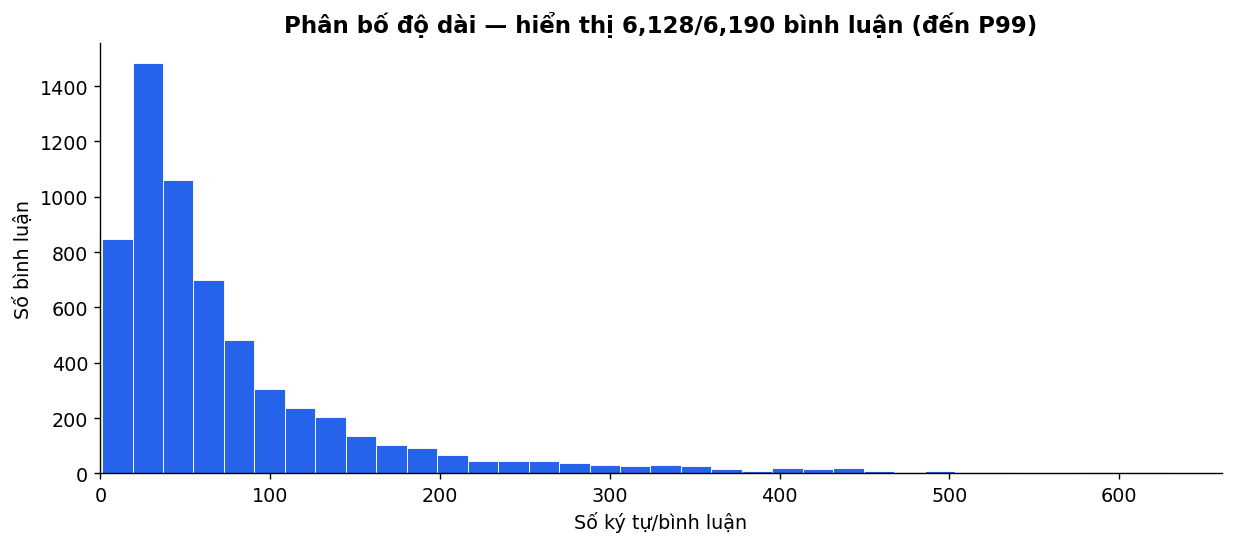

**Nhận xét:** Trung vị **49 ký tự**, có **60 bình luận dưới 5 ký tự (1.0%)**. Biểu đồ không hiển thị 62 bình luận dài hơn 630 ký tự. Bình luận ngắn và dài cần xem nội dung; không tự xóa chỉ vì độ dài.

,comment,char_count,post_url
4298,"Có lẽ bộ phim “Mưa đỏ” sẽ được chiếu cho tất cả các bạn học sinh, sinh viên Việt Nam v...",5151,https://www.facebook.com/PhimMuaDo/posts/pfbid05C6Hqj4szMEEp3c58ra4xCnYo9TStQY4sw7S4iz...
6090,Đây là bài viết của con tôi cảm nhận về cuộc chiến Thành Cổ sau khi xem bộ phim Mưa Đ...,3710,https://www.facebook.com/PhimMuaDo/posts/pfbid0KSNmaM2osWMfvqXhUY2FsPWxeoSik6GbmmPhQ5q...
3395,Đây là bài viết của con tôi cảm nhận về cuộc chiến Thành Cổ sau khi xem bộ phim Mưa Đ...,3710,https://www.facebook.com/PhimMuaDo/posts/pfbid02PTyV4AENYRGjKDktiEeiDXRxd75Rn4g4utEmEL...


In [7]:
display(df[['char_count', 'space_units']].describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1)
        .rename(columns={'char_count': 'số_ký_tự', 'space_units': 'đơn_vị_khoảng_trắng'}))
limit = max(1, int(np.ceil(df.char_count.quantile(.99))))
shown = df.loc[df.char_count.le(limit), 'char_count']
fig, ax = plt.subplots()
ax.hist(shown, bins=35, color=BLUE, edgecolor='white', linewidth=.5)
ax.set(xlabel='Số ký tự/bình luận', ylabel='Số bình luận',
       title=f'Phân bố độ dài — hiển thị {len(shown):,}/{len(df):,} bình luận (đến P99)')
ax.set_xlim(left=0)
fig.tight_layout(); plt.show()
short = int(df.char_count.lt(5).sum())
display(Markdown(f'**Nhận xét:** Trung vị **{df.char_count.median():.0f} ký tự**, '
                 f'có **{short:,} bình luận dưới 5 ký tự ({short/len(df):.1%})**. '
                 f'Biểu đồ không hiển thị {len(df)-len(shown)} bình luận dài hơn {limit} ký tự. '
                 'Bình luận ngắn và dài cần xem nội dung; không tự xóa chỉ vì độ dài.'))
display(df.sort_values('char_count', ascending=False)[['comment', 'char_count', 'post_url']].head(3))

## Phân bố theo bài và loại đường dẫn

Mã P001, P002… chỉ để biểu đồ gọn; bảng bên dưới chứa URL đối chiếu.
Nhiều bình luận ở một số ít bài có thể làm dữ liệu phụ thuộc mạnh vào chủ đề/đối tượng của các bài đó.

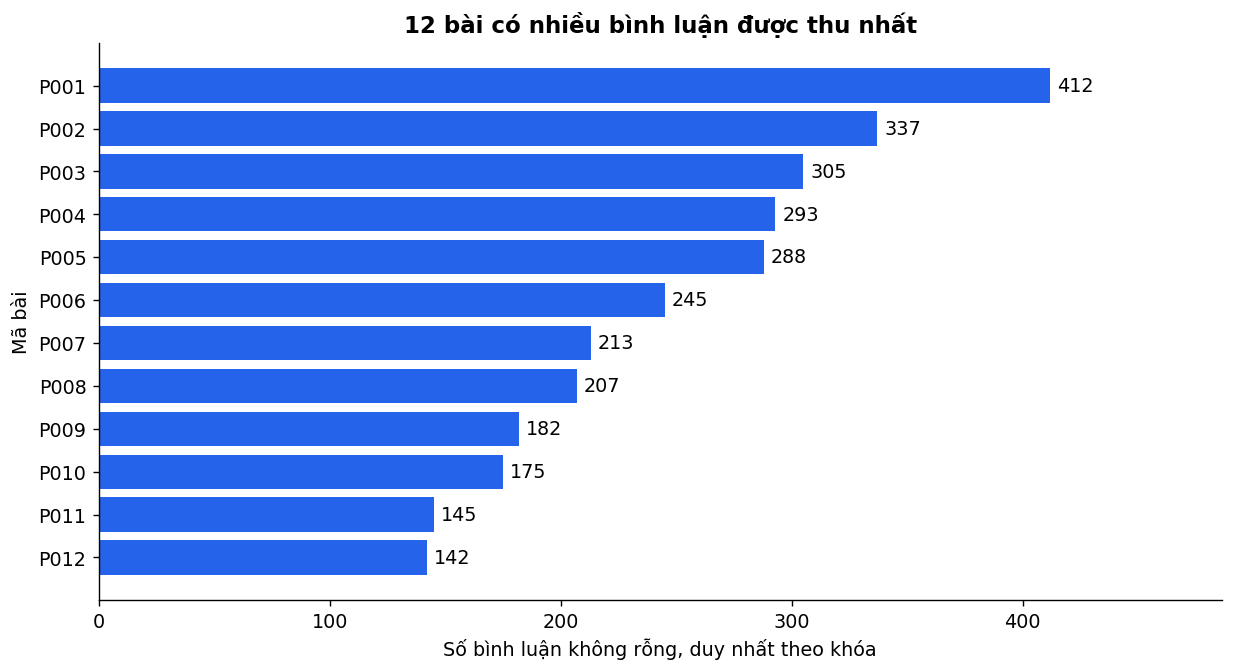

,mã_bài,post_url,số_bình_luận
0,P001,https://www.facebook.com/PhimMuaDo/posts/pfbid02MUycPz8noqQLvsn5vvpVjDCkrucNAjf6teHpZX...,412
1,P002,https://www.facebook.com/reel/1521398292369988/,337
2,P003,https://www.facebook.com/reel/995177076020841/,305
3,P004,https://www.facebook.com/reel/801584078926735/,293
4,P005,https://www.facebook.com/PhimMuaDo/posts/pfbid0BC32tfHwcSV2MxJobA9LQ6DdEwUGMWERnxgHy1t...,288
5,P006,https://www.facebook.com/reel/25100265262893495/,245
6,P007,https://www.facebook.com/PhimMuaDo/posts/pfbid02QHNYdMRfJ1EGmcincESkEWcbhtPCFZQFe64C4k...,213
7,P008,https://www.facebook.com/PhimMuaDo/posts/pfbid0pmDMwTdkTXiUYitBzpYc9wKTXTtn2u57jfJ9wCk...,207
8,P009,https://www.facebook.com/PhimMuaDo/posts/pfbid0KHrer4tBnAN3JvLdcb4yooYfXj6MXRNRWWRd4C8...,182
9,P010,https://www.facebook.com/reel/1380839956720665/,175


**Nhận xét:** 5 bài nhiều dữ liệu nhất chiếm **26.4%** tổng số bình luận phân tích. Khi huấn luyện nên chia theo bài để giảm rò rỉ giữa train và test. Không suy ra lượt tương tác thật từ số bình luận crawler đã lấy được.

In [8]:
post_counts = (df.loc[df['_url'].ne('')].groupby('_url').size()
               .rename('số_bình_luận').sort_values(ascending=False).rename_axis('post_url').reset_index())
post_counts['mã_bài'] = [f'P{i+1:03}' for i in range(len(post_counts))]
top = post_counts.head(12).iloc[::-1]
top5_share = post_counts.head(5)['số_bình_luận'].sum() / len(df)
if not top.empty:
    fig, ax = plt.subplots(figsize=(10, 5.5))
    bars = ax.barh(top['mã_bài'], top['số_bình_luận'], color=BLUE)
    ax.bar_label(bars, padding=4)
    ax.set(xlabel='Số bình luận không rỗng, duy nhất theo khóa', ylabel='Mã bài',
           title=f'{len(top)} bài có nhiều bình luận được thu nhất')
    ax.set_xlim(0, max(top['số_bình_luận'].max(), 1) * 1.18)
    fig.tight_layout(); plt.show()
display(post_counts[['mã_bài', 'post_url', 'số_bình_luận']].head(12))
display(Markdown(f'**Nhận xét:** 5 bài nhiều dữ liệu nhất chiếm **{top5_share:.1%}** '
                 'tổng số bình luận phân tích. Khi huấn luyện nên chia theo bài để giảm rò rỉ giữa train và test. '
                 'Không suy ra lượt tương tác thật từ số bình luận crawler đã lấy được.'))

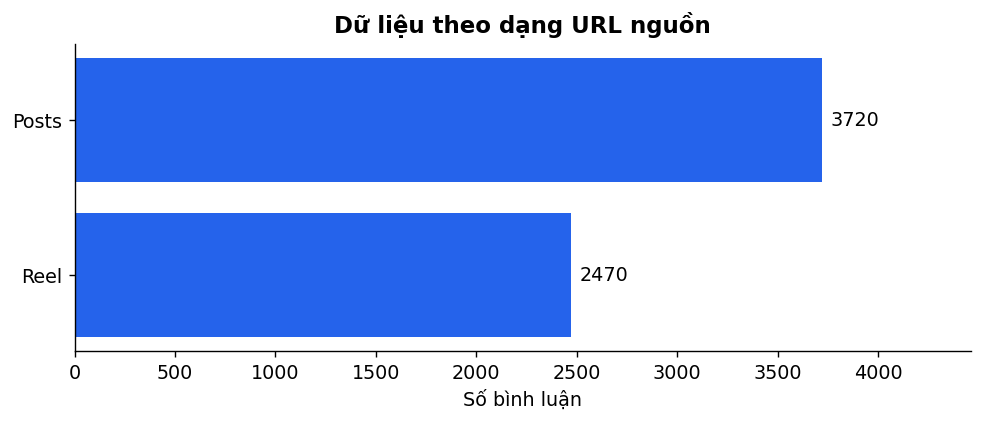

**Lưu ý:** Đây là dạng đường dẫn đã lưu, không phải số fanpage độc lập hay bằng chứng rằng Reel/Video có chất lượng dữ liệu tốt hơn.

In [9]:
def url_type(url):
    path = urlparse(url).path
    if '/reel/' in path: return 'Reel'
    if '/videos/' in path: return 'Video'
    if '/posts/' in path: return 'Posts'
    if 'permalink' in path: return 'Permalink'
    return 'Chưa nhận diện'

type_counts = df['_url'].map(url_type).value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(type_counts.index[::-1], type_counts.values[::-1], color=BLUE)
ax.bar_label(bars, padding=5)
ax.set(xlabel='Số bình luận', title='Dữ liệu theo dạng URL nguồn')
ax.set_xlim(0, max(type_counts.max(), 1) * 1.2)
fig.tight_layout(); plt.show()
display(Markdown('**Lưu ý:** Đây là dạng đường dẫn đã lưu, không phải số fanpage độc lập hay bằng chứng '
                 'rằng Reel/Video có chất lượng dữ liệu tốt hơn.'))

## Nội dung trùng, emoji và phản hồi

Giữ lại bằng chứng để duyệt thủ công. Các câu như “Hay quá” có thể được nhiều người viết độc lập.

In [10]:
traits = pd.DataFrame([
    ('Có emoji', int(df.has_emoji.sum())),
    ('Có URL trong nội dung', int(df.has_url.sum())),
    ('Có ID bình luận cha', reply_count),
], columns=['đặc_điểm', 'số_bình_luận'])
traits['tỷ_lệ_%'] = (traits['số_bình_luận'] / len(df) * 100).round(2)
display(traits)
text_repeats = (df.groupby('_text_key').agg(số_lần=('comment', 'size'), số_bài=('_url', 'nunique'))
                .query('số_lần > 1').sort_values('số_lần', ascending=False))
display(text_repeats.head(10).rename_axis('nội_dung_chuẩn_hóa').reset_index())
display(Markdown(f'**Nhận xét:** Có **{len(text_repeats):,} nhóm nội dung lặp** và '
                 f'**{same_text_duplicates:,} bản ngoài lần xuất hiện đầu**. '
                 'Đối chiếu nhãn ở các câu trùng trước khi huấn luyện; giữ emoji làm tín hiệu thay vì tự đổi thành nhãn Toxic.'))

,đặc_điểm,số_bình_luận,tỷ_lệ_%
0,Có emoji,1761,28.45
1,Có URL trong nội dung,52,0.84
2,Có ID bình luận cha,6,0.10


,nội_dung_chuẩn_hóa,số_lần,số_bài
0,nam mô a di đà phật,102,10
1,❤️,30,15
2,tuyệt vời,20,11
3,nam mô a di đà phật 🙏 🙏 🙏,17,2
4,chúc mừng mưa đỏ,16,7
5,quá tuyệt vời,16,11
6,❤️ ❤️ ❤️,10,6
7,nam mô a di đà phật!,10,2
8,a di đà phật,9,6
9,❤️ ❤️ ❤️ ❤️ ❤️,9,8


**Nhận xét:** Có **184 nhóm nội dung lặp** và **448 bản ngoài lần xuất hiện đầu**. Đối chiếu nhãn ở các câu trùng trước khi huấn luyện; giữ emoji làm tín hiệu thay vì tự đổi thành nhãn Toxic.

## Những đơn vị văn bản xuất hiện nhiều

Đếm bằng biểu thức chính quy, chưa tách từ tiếng Việt, không phải BoW/TF-IDF huấn luyện.
Thống kê này để nhận biết đặc điểm ngôn ngữ; không dùng tần suất từ để tự gán nhãn.

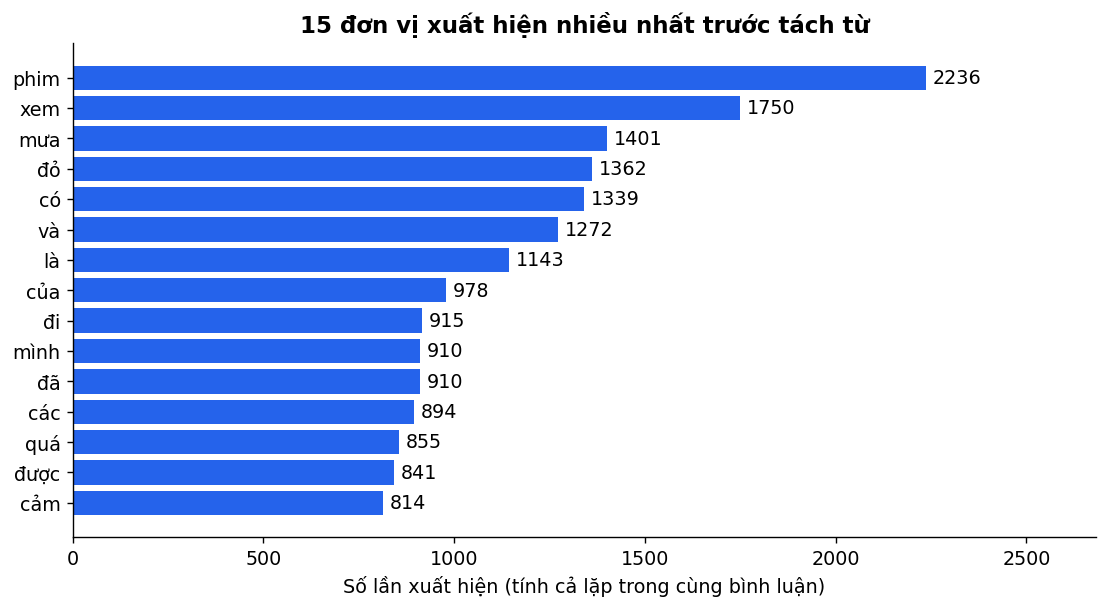

**Nhận xét:** Các từ phổ biến giúp kiểm tra sơ bộ ngôn ngữ và chủ đề. Cần đọc mẫu thủ công để xác nhận liên quan Mưa Đỏ; chưa có cơ sở kết luận tỷ lệ Toxic hoặc cảm xúc.

In [11]:
tokens = Counter(token for text in df.comment
                 for token in re.findall(r'(?u)\b[^\W\d_]{2,}\b', text.casefold()))
frequent = pd.DataFrame(tokens.most_common(15), columns=['đơn_vị', 'số_lần'])
if not frequent.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(frequent['đơn_vị'][::-1], frequent['số_lần'][::-1], color=BLUE)
    ax.bar_label(bars, padding=4)
    ax.set(xlabel='Số lần xuất hiện (tính cả lặp trong cùng bình luận)', title='15 đơn vị xuất hiện nhiều nhất trước tách từ')
    ax.set_xlim(0, frequent['số_lần'].max() * 1.2)
    fig.tight_layout(); plt.show()
display(Markdown('**Nhận xét:** Các từ phổ biến giúp kiểm tra sơ bộ ngôn ngữ và chủ đề. '
                 'Cần đọc mẫu thủ công để xác nhận liên quan Mưa Đỏ; chưa có cơ sở kết luận tỷ lệ Toxic hoặc cảm xúc.'))

## Nhãn Toxic/Non Toxic — chỉ thống kê nhãn thực có

Mặc định không suy đoán nhãn. Muốn kiểm tra nhãn đã duyệt, đặt `LABEL_FILE` ở ô cấu hình.
Nếu CSV crawl đã có cột `label`, notebook dùng cột đó. File nhãn riêng cần khóa `post_url + comment_id`.

In [12]:
label_counts = None
label_note = 'Chưa cung cấp nhãn: chưa thể đánh giá mất cân bằng Toxic/Non Toxic hoặc chất lượng nhãn.'
if LABEL_FILE is not None or 'label' in columns:
    labels = pd.read_csv(Path(LABEL_FILE), dtype=str, keep_default_na=False, encoding='utf-8-sig') if LABEL_FILE is not None else raw.copy()
    need = {'post_url', 'comment_id', 'label'}
    if not need.issubset(labels):
        raise ValueError(f'File nhãn thiếu: {need-set(labels.columns)}')
    labels['_url'] = labels.post_url.map(normalize_url)
    labels['_id'] = labels.comment_id.str.strip()
    labels['label'] = labels.label.str.strip()
    labels = labels.loc[labels['_url'].ne('') & labels['_id'].ne('')].copy()
    conflicts = labels.loc[labels.label.ne('')].groupby(['_url', '_id']).label.nunique()
    if conflicts.gt(1).any():
        raise ValueError('Cùng ID có nhiều nhãn khác nhau; cần duyệt lại.')
    labels = labels.assign(_has_label=labels.label.ne('')).sort_values('_has_label').drop_duplicates(['_url', '_id'], keep='last')
    joined = df[['_url', '_id']].merge(labels[['_url', '_id', 'label']], how='left', on=['_url', '_id'], validate='many_to_one')
    label_counts = joined.label.fillna('').map({'0': 'Non Toxic (0)', '1': 'Toxic (1)', '': 'Chưa gán'}).fillna('Nhãn không hợp lệ').value_counts()
    display(label_counts.rename('số_bình_luận').to_frame())
    fig, ax = plt.subplots(figsize=(8, 3.5))
    bars = ax.barh(label_counts.index[::-1], label_counts.values[::-1], color=BLUE)
    ax.bar_label(bars, padding=5)
    ax.set(xlabel='Số bình luận trong CSV khảo sát', title='Nhãn thực tế khớp theo URL + ID')
    ax.set_xlim(0, max(label_counts.max(), 1) * 1.2)
    fig.tight_layout(); plt.show()
    label_note = 'Đã đối chiếu nhãn theo khóa. Nhãn trống/không hợp lệ phải được xử lý trước khi huấn luyện.'
display(Markdown('**Nhận xét:** ' + label_note))

**Nhận xét:** Chưa cung cấp nhãn: chưa thể đánh giá mất cân bằng Toxic/Non Toxic hoặc chất lượng nhãn.

## Nhận xét và việc cần làm tiếp

Các gạch đầu dòng được tạo từ kết quả vừa tính; có thể dùng làm khung viết phần mô tả dữ liệu trong báo cáo.

In [13]:
collected = pd.to_datetime(raw.collected_at, errors='coerce', utc=True)
valid_times = collected.dropna().dt.tz_convert('Asia/Ho_Chi_Minh')
takeaways = [
    f'**Quy mô:** {len(df):,} bình luận không rỗng sau loại trùng khóa, trên {known_urls} URL nguồn; chưa phải số mẫu đã duyệt.',
    f'**Chất lượng:** {len(repeated_headers)} dòng tiêu đề lặp; {len(malformed)} bản ghi sai số cột; '
    f'{identity_duplicates} dòng trùng khóa; {int((~raw._has_text).sum())} dòng nội dung rỗng.',
    f'**Nội dung:** trung vị {df.char_count.median():.0f} ký tự; {int(df.has_emoji.sum()):,} bình luận có emoji '
    f'({df.has_emoji.mean():.1%}); {same_text_duplicates:,} bản nội dung lặp cần kiểm tra.',
    f'**Nguồn:** 5 bài nhiều dữ liệu nhất chiếm {top5_share:.1%}; giữ cùng bài trong cùng tập khi chia train/validation/test.',
    '**Nhãn:** ' + label_note,
    '**Giới hạn:** dữ liệu thu từ các URL này chưa đại diện cho toàn bộ Facebook; chưa xác minh tự động '
    'mọi dòng đều nói về Mưa Đỏ hoặc đã lấy đủ bình luận từng bài.',
    '**Bước tiếp theo:** kiểm tra mẫu lấy nhầm giao diện/không liên quan; xử lý các câu trùng có nhãn mâu thuẫn; '
    'gán và duyệt nhãn thủ công trước khi huấn luyện. Không tự xóa từ phủ định, từ tục hay bình luận ngắn.',
]
if expected:
    takeaways.insert(2, f'**Độ phủ:** {has_data}/{len(expected)} URL trong danh sách hiện tại đã có dữ liệu; '
                     f'{no_data} URL chưa có; đây không phải tỷ lệ cào đủ bình luận.')
if bad_links:
    takeaways.append(f'**Giới hạn đối chiếu:** {len(bad_links)} dòng URL đầu vào chưa chuẩn hóa được; cần đổi link chia sẻ thành permalink trước khi xác nhận đã/chưa crawl.')
if len(valid_times):
    takeaways.append(f'**Thời điểm thu/đọc lại ghi trong CSV:** {valid_times.min():%d/%m/%Y %H:%M} '
                     f'đến {valid_times.max():%d/%m/%Y %H:%M} (giờ Việt Nam); không phải ngày đăng bình luận.')
display(Markdown((chr(10)*2).join('- '+line for line in takeaways)))

- **Quy mô:** 6,190 bình luận không rỗng sau loại trùng khóa, trên 96 URL nguồn; chưa phải số mẫu đã duyệt.

- **Chất lượng:** 1 dòng tiêu đề lặp; 0 bản ghi sai số cột; 0 dòng trùng khóa; 0 dòng nội dung rỗng.

- **Nội dung:** trung vị 49 ký tự; 1,761 bình luận có emoji (28.4%); 448 bản nội dung lặp cần kiểm tra.

- **Nguồn:** 5 bài nhiều dữ liệu nhất chiếm 26.4%; giữ cùng bài trong cùng tập khi chia train/validation/test.

- **Nhãn:** Chưa cung cấp nhãn: chưa thể đánh giá mất cân bằng Toxic/Non Toxic hoặc chất lượng nhãn.

- **Giới hạn:** dữ liệu thu từ các URL này chưa đại diện cho toàn bộ Facebook; chưa xác minh tự động mọi dòng đều nói về Mưa Đỏ hoặc đã lấy đủ bình luận từng bài.

- **Bước tiếp theo:** kiểm tra mẫu lấy nhầm giao diện/không liên quan; xử lý các câu trùng có nhãn mâu thuẫn; gán và duyệt nhãn thủ công trước khi huấn luyện. Không tự xóa từ phủ định, từ tục hay bình luận ngắn.

- **Giới hạn đối chiếu:** 2 dòng URL đầu vào chưa chuẩn hóa được; cần đổi link chia sẻ thành permalink trước khi xác nhận đã/chưa crawl.

- **Thời điểm thu/đọc lại ghi trong CSV:** 02/11/2026 15:57 đến 04/11/2026 10:51 (giờ Việt Nam); không phải ngày đăng bình luận.

## Kiểm tra tính nhất quán

Ô cuối phải chạy thành công. Các kiểm tra không khẳng định dữ liệu Facebook đã đầy đủ hay nhãn đã đúng.

In [14]:
assert len(raw) >= len(df)
assert not df.duplicated('_comment_key').any()
assert int(post_counts['số_bình_luận'].sum()) == int(df['_url'].ne('').sum())
assert (df.char_count > 0).all()
if expected:
    assert has_data + no_data == len(expected)
    assert coverage['post_url'].is_unique
print('Đạt kiểm tra số dòng, khóa bình luận, tổng theo bài và độ phủ danh sách.')
print('CSV nguồn thay đổi trong lúc chạy:', CSV_FILE.read_bytes() != csv_bytes)
print('Không sửa CSV gốc hoặc tự gán nhãn.')

Đạt kiểm tra số dòng, khóa bình luận, tổng theo bài và độ phủ danh sách.
CSV nguồn thay đổi trong lúc chạy: False
Không sửa CSV gốc hoặc tự gán nhãn.
